# Problem
Goal:  to determine the early readmission of the patient within 30 days of discharge </br>
Problem: failure to provide proper diabetes care not only increases the managing costs for the hospitals (as the patients are readmitted) but also impacts the morbidity and mortality of the patients, who may face complications associated with diabetes.

# Dataset utilizados
diabetic_data

In [ ]:
# @title
from google.colab import drive
from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score, confusion_matrix
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

# Load the dataset with pandas using the file path
base_path = '/content/drive/MyDrive/Projectos/'
df = pd.read_csv(base_path + 'diabetic_data.csv', keep_default_na=False)
df = df.replace('?', np.nan)

display(df.head(5).style.hide(axis='index'))

Mounted at /content/drive


encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
2278392,8222157,Caucasian,Female,[0-10),nan,6,25,1,1,nan,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,nan,nan,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
149190,55629189,Caucasian,Female,[10-20),nan,1,1,7,3,nan,nan,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
64410,86047875,AfricanAmerican,Female,[20-30),nan,1,1,7,2,nan,nan,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
500364,82442376,Caucasian,Male,[30-40),nan,1,1,7,2,nan,nan,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
16680,42519267,Caucasian,Male,[40-50),nan,1,1,7,1,nan,nan,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# Contar duplicados basados en 'patient_nbr'
total_pacientes_unicos = df['patient_nbr'].nunique()
total_registros = len(df)
registros_duplicados = df.duplicated(subset=['patient_nbr']).sum()

print(f"Total de registros en el dataset: {total_registros}")
print(f"Total de pacientes únicos: {total_pacientes_unicos}")
print(f"Número de registros que son de pacientes recurrentes (duplicados): {registros_duplicados}")

# Opcional: Mostrar los pacientes con más registros
print("\nPacientes con mayor número de encuentros (Top 5):")
display(df['patient_nbr'].value_counts().head(5))

Total de registros en el dataset: 101766
Total de pacientes únicos: 71518
Número de registros que son de pacientes recurrentes (duplicados): 30248

Pacientes con mayor número de encuentros (Top 5):


,count
patient_nbr,
88785891,40
43140906,28
88227540,23
1660293,23
23199021,23


# Dataset Analysis

1. Clean up, replace ? w/Nan
2. Count Nan by column
3. Delete constant columns (examide, citoglipton, where almost is No)
4. Delete records w/ discharge_disposition_id like Expired, Hospice (11, 13, 14, 19, 20, 21)
5. Target binarization: The original target readmitted has three classes: <30 (readmitted within 30 days), >30 (readmitted after 30 days) and NO (not readmitted). Since the business question focuses on <b>readmission within 30 days</b>, the target was converted to a binary variable: <30 = 1 and >30 + NO = 0.
6. Handling duplicated records: the first row was chosen instead of the last because the last one is biased toward "no readmission": if the patient had been readmitted, that readmission would appear as a later encounter.
7. EDA analysis
8. Reagruping categorical var. (admission_type_id, discharge_disposition_id and admission_source_id, diag1/2/3): use the mapping file to merge codes with a similar meaning into a few groups with clear names.
9. Correlation Analysis and Feature Selection
10. Data procesing and modeling
11. Evaluation







In [ ]:
# 1.2.  Reemplazar los valores '?' por NaN en el DataFrame de manera persistente
df = df.replace('?', np.nan)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
nulos = df.isnull().mean().mul(100).round(2)
nulos[nulos > 0].sort_values(ascending=False)

,0
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


In [ ]:
# 3.  Delete constant columns / columns nan
# weight, payer_code, medical_specialty, max_glu_serum, A1Cresult

columns_to_drop = ['weight', 'payer_code', 'medical_specialty']
df = df.drop(columns=columns_to_drop, errors='ignore')

resumen = pd.DataFrame({
    'valor_dominante': df.apply(lambda col: col.value_counts(dropna=False).index[0]),
    'pct': df.apply(lambda col: col.value_counts(normalize=True, dropna=False).iloc[0] * 100).round(3)
}).sort_values('pct', ascending=False)

resumen.head(25)

# Removal of low-variance medication columns
# Medication columns in which more than 99% of records have the value "No" were removed,
# since almost no patients received those drugs.
no_changes_dosis = resumen[(resumen['valor_dominante'] == 'No') & (resumen['pct'] > 85)].index.tolist()
df = df.drop(columns=no_changes_dosis, errors='ignore')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 26 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   admission_type_id         101766 non-null  int64 
 6   discharge_disposition_id  101766 non-null  int64 
 7   admission_source_id       101766 non-null  int64 
 8   time_in_hospital          101766 non-null  int64 
 9   num_lab_procedures        101766 non-null  int64 
 10  num_procedures            101766 non-null  int64 
 11  num_medications           101766 non-null  int64 
 12  number_outpatient         101766 non-null  int64 
 13  number_emergency          101766 non-null  int64 
 14  numb

In [ ]:
# 4. Delete row w/patients in Hospice or expired
disposition_ids_excluded = [11, 13, 14, 19, 20, 21]
mask = df['discharge_disposition_id'].isin(disposition_ids_excluded)
print('Deleted rows:', mask.sum())
df.loc[mask, 'discharge_disposition_id'].value_counts()

df = df[~mask]
print('Remined rows:', len(df))

Deleted rows: 2423
Remined rows: 99343


In [ ]:
# 5. Target: <30 => 1, >30 -> 0 - Verify imbalanced classifications
readm_values = ['NO', '>30', '<30']

tabla = pd.DataFrame({
    'count': df['readmitted'].value_counts().reindex(readm_values),
    'percent': df['readmitted'].value_counts(normalize=True).reindex(readm_values).mul(100).round(2)
})
tabla.loc['Total'] = [tabla['count'].sum(), tabla['percent'].sum()]
tabla['count'] = tabla['count'].astype(int)

display(tabla.style.format({'count': '{:,}', 'percent': '{:.2f}%'}))

,count,percent
readmitted,,
NO,"52,527",52.87%
>30,"35,502",35.74%
<30,"11,314",11.39%
Total,"99,343",100.00%


In [ ]:
# Binarize readmitted - Graphic w/classes
df['readmitted_binary'] = (df['readmitted'] == '<30').astype(int)
df['readmitted_binary'].value_counts(normalize=True).mul(100).round(2)

,proportion
readmitted_binary,
0,88.61
1,11.39


In [ ]:
# 6. Handling duplicated records - readmissions patients
records_by_paciente = df['patient_nbr'].value_counts()

print('Records:', len(df))
print('Unique Patients:', df['patient_nbr'].nunique())
print('Duplicated Patients:', (records_by_paciente > 1).sum())
# how many pacienes has 1, 2, 3... admissions
records_by_paciente.value_counts().sort_index().head(10)


Records: 99343
Unique Patients: 69990
Duplicated Patients: 16341


,count
count,
1,53649
2,10218
3,3233
4,1354
5,691
6,338
7,192
8,112
9,67


In [ ]:
df = df.sort_values('encounter_id').drop_duplicates(subset='patient_nbr', keep='first')
print('Remined records:', len(df))

Remined records: 69990


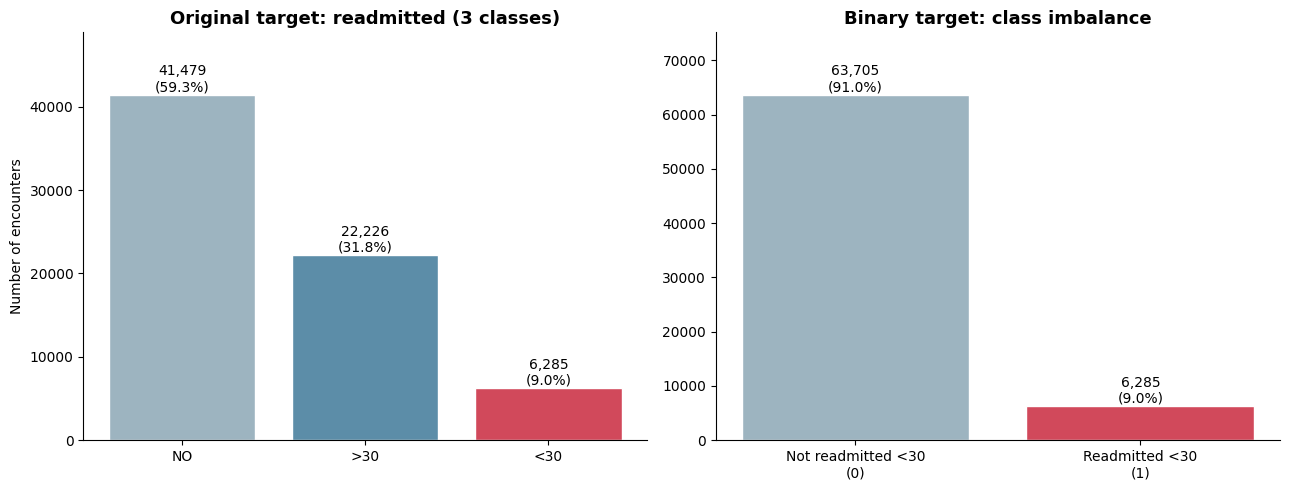

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: clases originales (readmitted)
conteo = df['readmitted'].value_counts()
conteo = conteo.reindex([v for v in ['NO', '>30', '<30'] if v in conteo.index])
colores = ['#9DB4C0', '#5C8DA8', '#D1495B']
bars = axes[0].bar(conteo.index, conteo.values, color=colores[:len(conteo)], edgecolor='white')
for b, v in zip(bars, conteo.values):
    axes[0].text(b.get_x() + b.get_width()/2, v, f'{v:,}\n({v/conteo.sum():.1%})',
                 ha='center', va='bottom', fontsize=10)
axes[0].set_title('Original target: readmitted (3 classes)', fontsize=13, weight='bold')
axes[0].set_ylabel('Number of encounters')
axes[0].set_ylim(0, conteo.max() * 1.18)

# Panel 2: target binario (readmitted_binary)
binario = df['readmitted_binary'].value_counts().sort_index()
etiquetas = ['Not readmitted <30\n(0)', 'Readmitted <30\n(1)']
bars = axes[1].bar(etiquetas, binario.values, color=['#9DB4C0', '#D1495B'], edgecolor='white')
for b, v in zip(bars, binario.values):
    axes[1].text(b.get_x() + b.get_width()/2, v, f'{v:,}\n({v/binario.sum():.1%})',
                 ha='center', va='bottom', fontsize=10)
axes[1].set_title('Binary target: class imbalance', fontsize=13, weight='bold')
axes[1].set_ylim(0, binario.max() * 1.18)

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69990.0,4.27,2.93,1.0,2.0,3.0,6.0,14.0
num_lab_procedures,69990.0,42.88,19.89,1.0,31.0,44.0,57.0,132.0
num_procedures,69990.0,1.43,1.76,0.0,0.0,1.0,2.0,6.0
num_medications,69990.0,15.67,8.29,1.0,10.0,14.0,20.0,81.0
number_outpatient,69990.0,0.28,1.06,0.0,0.0,0.0,0.0,42.0
number_emergency,69990.0,0.10,0.51,0.0,0.0,0.0,0.0,42.0
number_inpatient,69990.0,0.18,0.60,0.0,0.0,0.0,0.0,12.0
number_diagnoses,69990.0,7.22,2.00,1.0,6.0,8.0,9.0,16.0


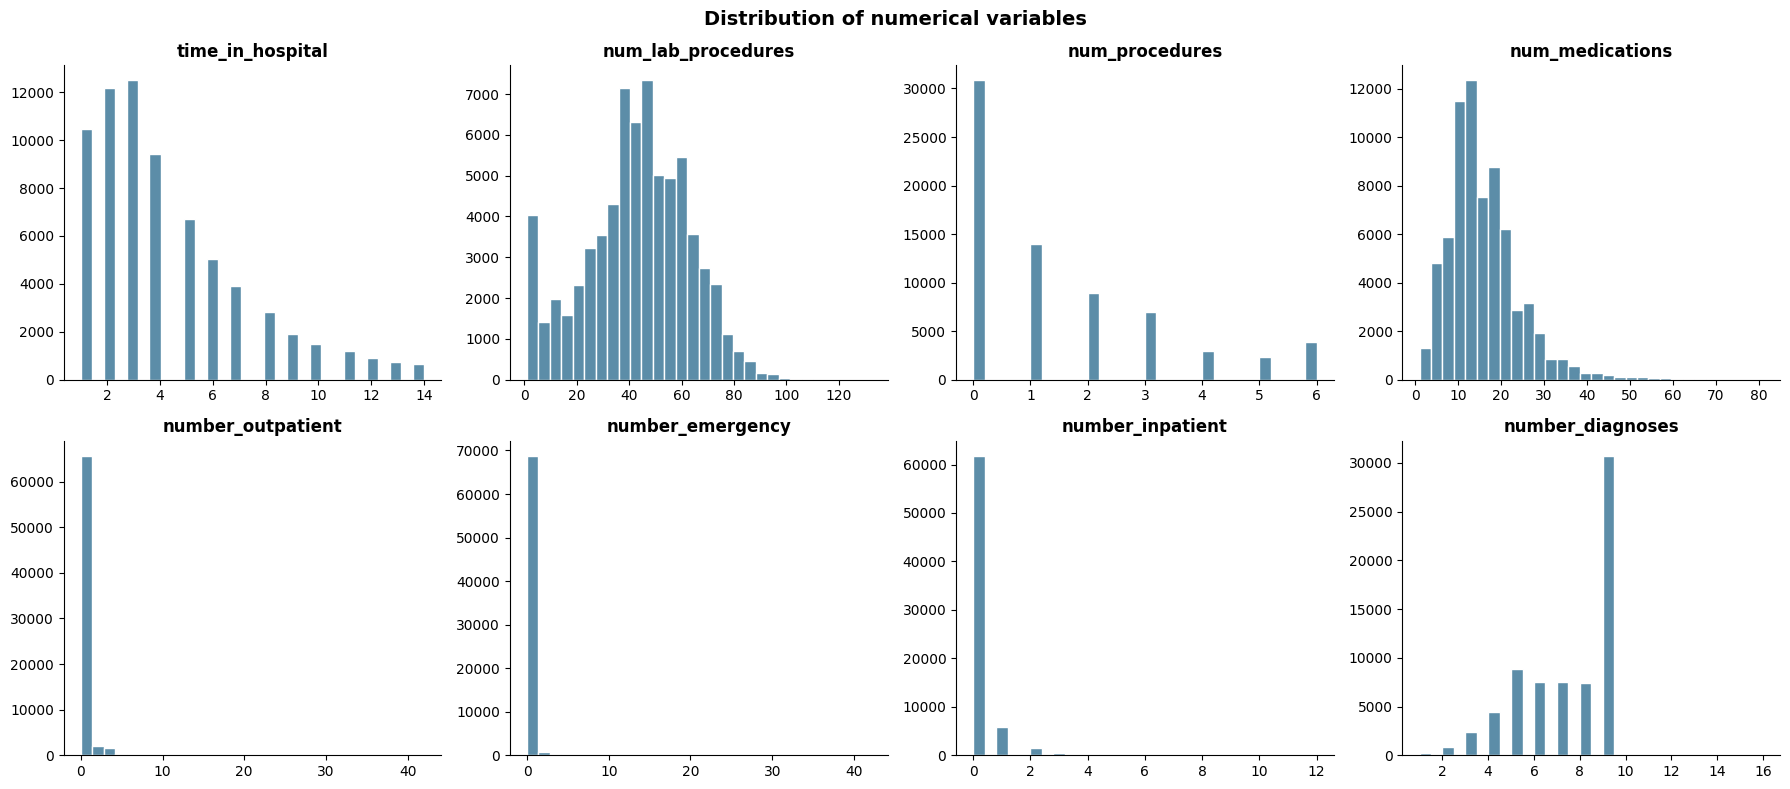

In [ ]:
# 7. EDA analysis
# Var. numerics and categoric

num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

display(df[num_cols].describe().T.round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(df[col], bins=30, color='#5C8DA8', edgecolor='white')
    ax.set_title(col, weight='bold')
    ax.spines[['top', 'right']].set_visible(False)
plt.suptitle('Distribution of numerical variables', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

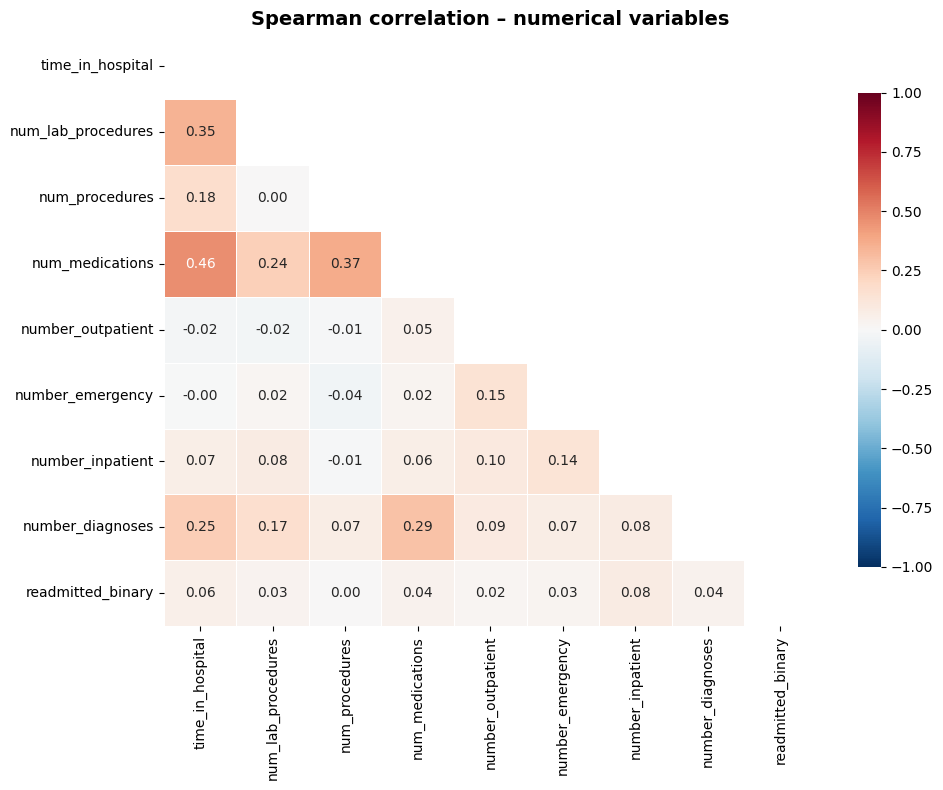

In [ ]:
corr = df[num_cols + ['readmitted_binary']].corr(method='spearman')

mask = np.triu(np.ones_like(corr, dtype=bool))   # oculta la mitad repetida
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Spearman correlation – numerical variables', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

<b>Correlation analysis – numerical variables</b>

No strong correlations (|ρ| > 0.7) were found among numerical predictors, so multicollinearity is not a concern. The highest correlation is between time_in_hospital and num_medications (ρ = 0.46), which is moderate and clinically expected. Correlations with the target are weak, as expected for an imbalanced binary outcome; number_inpatient (0.08) and time_in_hospital (0.06) show the strongest association, while num_procedures (0.00) shows none and is a candidate for removal.

In [ ]:
cat_cols = ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id',
            'admission_source_id', 'A1Cresult', 'max_glu_serum', 'insulin', 'metformin',
            'change', 'diabetesMed']

# Los IDs son categorías, no números
for c in ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']:
    df[c] = df[c].astype(str)

for col in cat_cols:
    t = df.groupby(col)['readmitted_binary'].agg(count='count', readmit_rate='mean')
    t['percent'] = (t['count'] / len(df) * 100).round(2)
    t['readmit_rate'] = (t['readmit_rate'] * 100).round(2)
    t = t[['count', 'percent', 'readmit_rate']].sort_values('count', ascending=False)
    print(f'\n=== {col} ===')
    display(t)


=== race ===


,count,percent,readmit_rate
race,,,
Caucasian,52305,74.73,9.19
AfricanAmerican,12627,18.04,8.67
Hispanic,1501,2.14,8.13
Other,1150,1.64,6.87
Asian,488,0.70,8.40



=== gender ===


,count,percent,readmit_rate
gender,,,
Female,37239,53.21,9.04
Male,32748,46.79,8.92
Unknown/Invalid,3,0.00,0.00



=== age ===


...

,count,percent,readmit_rate
metformin,,,
No,55085,78.70,9.16
Steady,13636,19.48,8.34
Up,834,1.19,6.95
Down,435,0.62,10.11



=== change ===


,count,percent,readmit_rate
change,,,
No,38493,55.0,8.60
Ch,31497,45.0,9.44



=== diabetesMed ===


,count,percent,readmit_rate
diabetesMed,,,
Yes,53304,76.16,9.42
No,16686,23.84,7.56


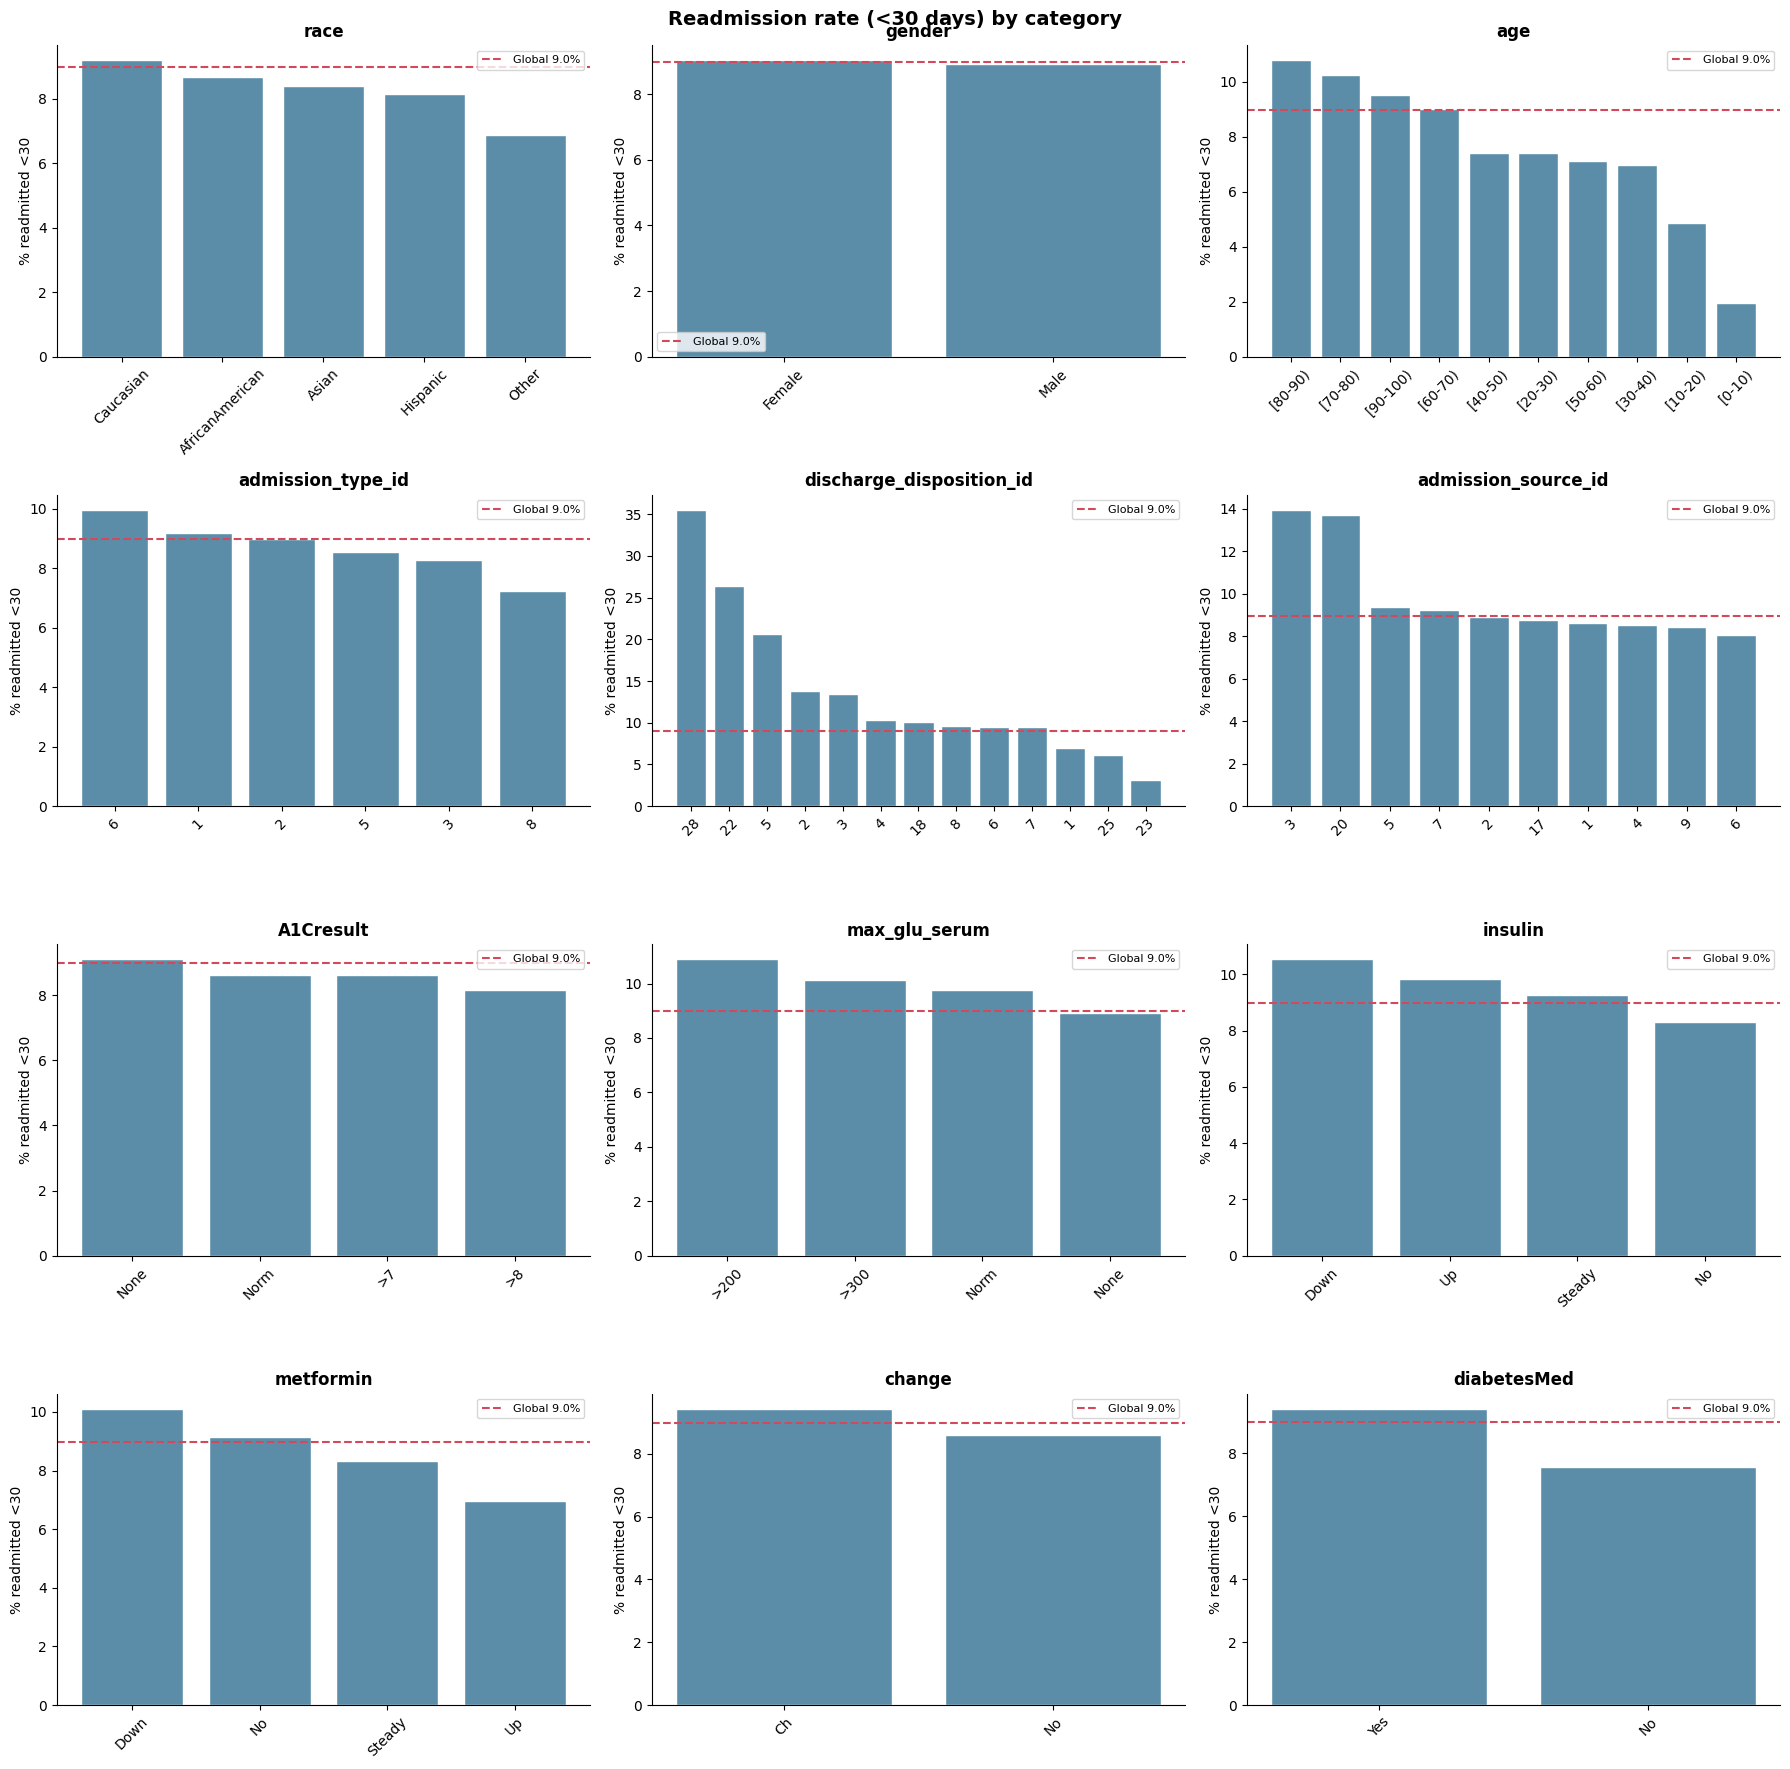

In [ ]:
tasa_global = df['readmitted_binary'].mean() * 100

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for ax, col in zip(axes.flat, cat_cols):
    tasa = df.groupby(col)['readmitted_binary'].agg(['mean', 'count'])
    tasa = tasa[tasa['count'] >= 50]          # oculta categorías con muy pocos casos
    tasa = tasa.sort_values('mean', ascending=False)
    ax.bar(tasa.index.astype(str), tasa['mean'] * 100, color='#5C8DA8', edgecolor='white')
    ax.axhline(tasa_global, color='#D1495B', linestyle='--', label=f'Global {tasa_global:.1f}%')
    ax.set_title(col, weight='bold')
    ax.set_ylabel('% readmitted <30')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
plt.suptitle('Readmission rate (<30 days) by category', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

<b>EDA conclusions – categorical variables</b>

Strong signal
*   discharge_disposition_id is the most discriminative variable. Patients transferred to another facility have much higher readmission rates than those discharged home: psychiatric hospital (35%), rehabilitation facility (26%), another inpatient institution (20%), short-term hospital or skilled nursing facility (~13%). Patients discharged home (the largest group) show ~7%, below the global rate of 9%.
*   age shows a clear gradient: readmission risk increases with age, from ~2% in [0–10) to ~11% in [80–90). Younger groups have few cases.
*   admission_source_id: HMO referrals (code 3) and unmapped sources (code 20) reach ~14%; the remaining sources stay close to the global rate.

Moderate signal
*   diabetesMed: patients on diabetes medication show a higher rate (9.4%) than those without (7.5%).
*   insulin: dose adjustments (Up/Down) are associated with higher risk (~10%) than no insulin (~8%), suggesting less stable patients.
*   metformin: patients on metformin (Steady/Up) show lower risk, possibly reflecting better-controlled diabetes.

Weak or no signal
*   gender: no meaningful difference; candidate for removal.
*   race: small differences; the “Other” category has few cases.
*   A1Cresult: minimal differences between categories.
*   max_glu_serum: ~95% of patients were not tested, which limits its usefulness.
*   admission_type_id: small differences across types (7–10%).
*   change: small difference, likely redundant with insulin and diabetesMed; to be confirmed with Cramér’s V.

In [ ]:
# 8. Reagruping var. categoricals
# --- discharge_disposition_id ---
discharge_map = {
    1: 'Home',
    6: 'Home_with_care', 8: 'Home_with_care',
    2: 'Transfer_hospital', 5: 'Transfer_hospital', 9: 'Transfer_hospital', 10: 'Transfer_hospital',
    15: 'Transfer_hospital', 23: 'Transfer_hospital', 27: 'Transfer_hospital',
    29: 'Transfer_hospital', 30: 'Transfer_hospital',
    3: 'Transfer_nursing', 4: 'Transfer_nursing', 24: 'Transfer_nursing',
    22: 'Transfer_rehab_psych', 28: 'Transfer_rehab_psych',
}   # the remaining categories (7 AMA, 12, 16, 17, 18 NULL, 25, 26) → 'Other/Unknown'

# --- admission_source_id ---
source_map = {
    7: 'Emergency_room',
    1: 'Referral', 2: 'Referral', 3: 'Referral',
    4: 'Transfer', 5: 'Transfer', 6: 'Transfer', 10: 'Transfer',
    18: 'Transfer', 22: 'Transfer', 25: 'Transfer', 26: 'Transfer',
}   # the remaining categories (no disponibile, NULL, no maped, births, etc.) → 'Other/Unknown'

# --- admission_type_id ---
type_map = {
    1: 'Emergency', 7: 'Emergency',   # 7 = Trauma Center
    2: 'Urgent',
    3: 'Elective',
}   # the remaining categories (4 Newborn, 5, 6, 8) → 'Other/Unknown'

df['discharge_group'] = df['discharge_disposition_id'].astype(int).map(discharge_map).fillna('Other/Unknown')
df['admission_source_group'] = df['admission_source_id'].astype(int).map(source_map).fillna('Other/Unknown')
df['admission_type_group'] = df['admission_type_id'].astype(int).map(type_map).fillna('Other/Unknown')


for col in ['discharge_group', 'admission_source_group', 'admission_type_group']:
    t = df.groupby(col)['readmitted_binary'].agg(count='count', readmit_rate='mean')
    t['readmit_rate'] = (t['readmit_rate'] * 100).round(2)
    print(f'\n=== {col} ===')
    display(t.sort_values('readmit_rate', ascending=False))


=== discharge_group ===


,count,readmit_rate
discharge_group,,
Transfer_rehab_psych,1501,26.92
Transfer_hospital,2772,15.44
Transfer_nursing,9357,13.22
Home_with_care,8364,9.54
Other/Unknown,3674,9.23
Home,44322,6.95



=== admission_source_group ===


,count,readmit_rate
admission_source_group,,
Emergency_room,37273,9.26
Other/Unknown,5084,8.89
Referral,22793,8.66
Transfer,4840,8.43



=== admission_type_group ===


,count,readmit_rate
admission_type_group,,
Other/Unknown,7902,9.31
Emergency,35498,9.18
Urgent,12803,8.97
Elective,13787,8.28


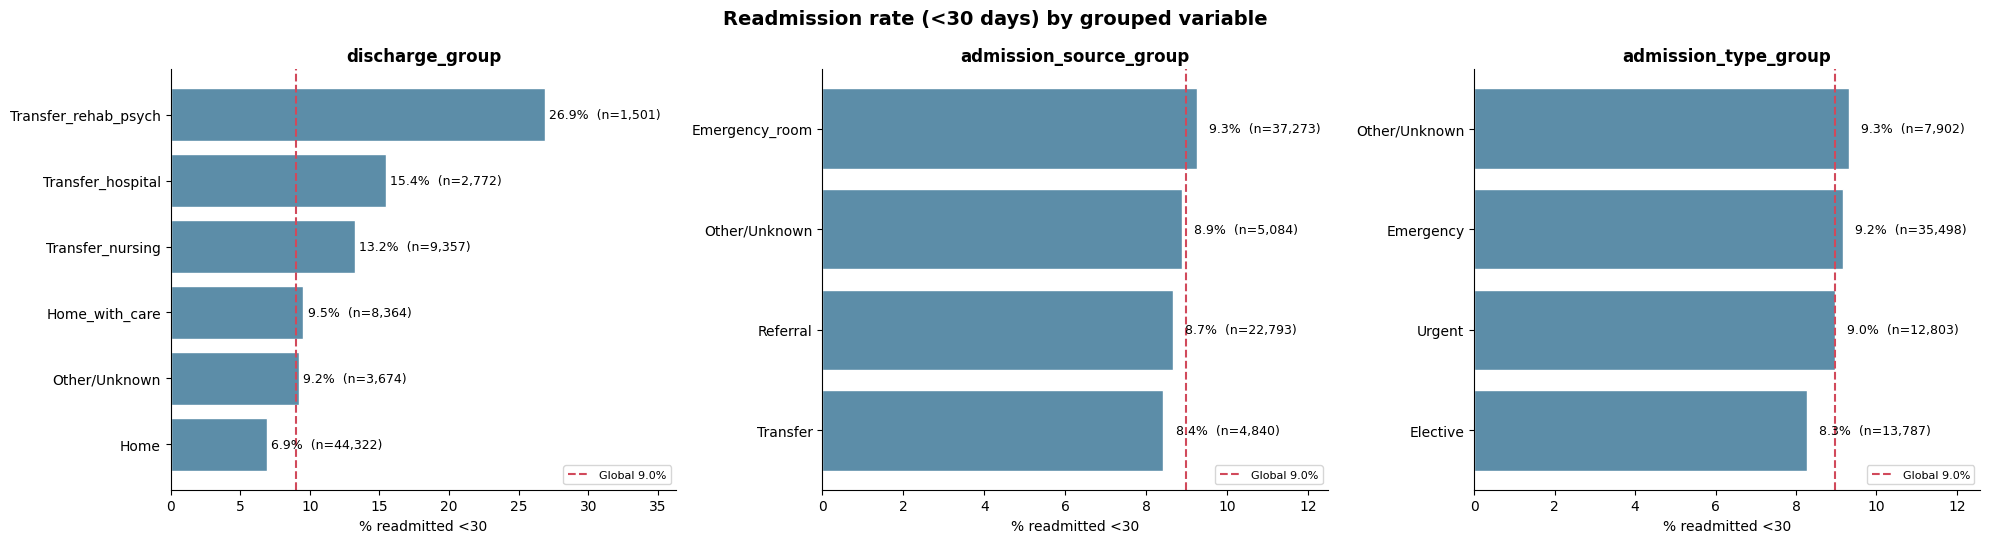

In [ ]:
grupos = ['discharge_group', 'admission_source_group', 'admission_type_group']
tasa_global = df['readmitted_binary'].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, col in zip(axes, grupos):
    t = df.groupby(col)['readmitted_binary'].agg(['mean', 'count'])
    t = t.sort_values('mean')
    bars = ax.barh(t.index, t['mean'] * 100, color='#5C8DA8', edgecolor='white')
    for b, (rate, n) in zip(bars, zip(t['mean'] * 100, t['count'])):
        ax.text(rate + 0.3, b.get_y() + b.get_height()/2, f'{rate:.1f}%  (n={n:,})',
                va='center', fontsize=9)
    ax.axvline(tasa_global, color='#D1495B', linestyle='--', label=f'Global {tasa_global:.1f}%')
    ax.set_title(col, weight='bold')
    ax.set_xlabel('% readmitted <30')
    ax.set_xlim(0, (t['mean'].max() * 100) * 1.35)
    ax.legend(fontsize=8, loc='lower right')
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Readmission rate (<30 days) by grouped variable', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# delete the original columns, keep ['discharge_map', 'source_map', 'type_map']
df = df.drop(columns=['discharge_disposition_id', 'admission_source_id', 'admission_type_id'], errors='ignore')
df.columns.tolist()

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'insulin',
 'change',
 'diabetesMed',
 'readmitted',
 'readmitted_binary',
 'discharge_group',
 'admission_source_group',
 'admission_type_group']

In [ ]:
# Grouping diag1,2,3
def agrupar_icd9(code):
    if pd.isna(code):
        return 'Missing'
    code = str(code)
    if code.startswith(('V', 'E')):
        return 'Other'
    c = float(code)
    if 390 <= c <= 459 or c == 785:
        return 'Circulatory'
    if 460 <= c <= 519 or c == 786:
        return 'Respiratory'
    if 520 <= c <= 579 or c == 787:
        return 'Digestive'
    if int(c) == 250:
        return 'Diabetes'
    if 800 <= c <= 999:
        return 'Injury'
    if 710 <= c <= 739:
        return 'Musculoskeletal'
    if 580 <= c <= 629 or c == 788:
        return 'Genitourinary'
    if 140 <= c <= 239:
        return 'Neoplasms'
    return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col + '_group'] = df[col].apply(agrupar_icd9)

for col in ['diag_1_group', 'diag_2_group', 'diag_3_group']:
    df[col] = df[col].replace('Missing', 'Other')

df['diag_1_group'].value_counts()


,count
diag_1_group,
Circulatory,21390
Other,12134
Respiratory,9491
Digestive,6488
Diabetes,5748
Injury,4696
Musculoskeletal,4064
Genitourinary,3441
Neoplasms,2538


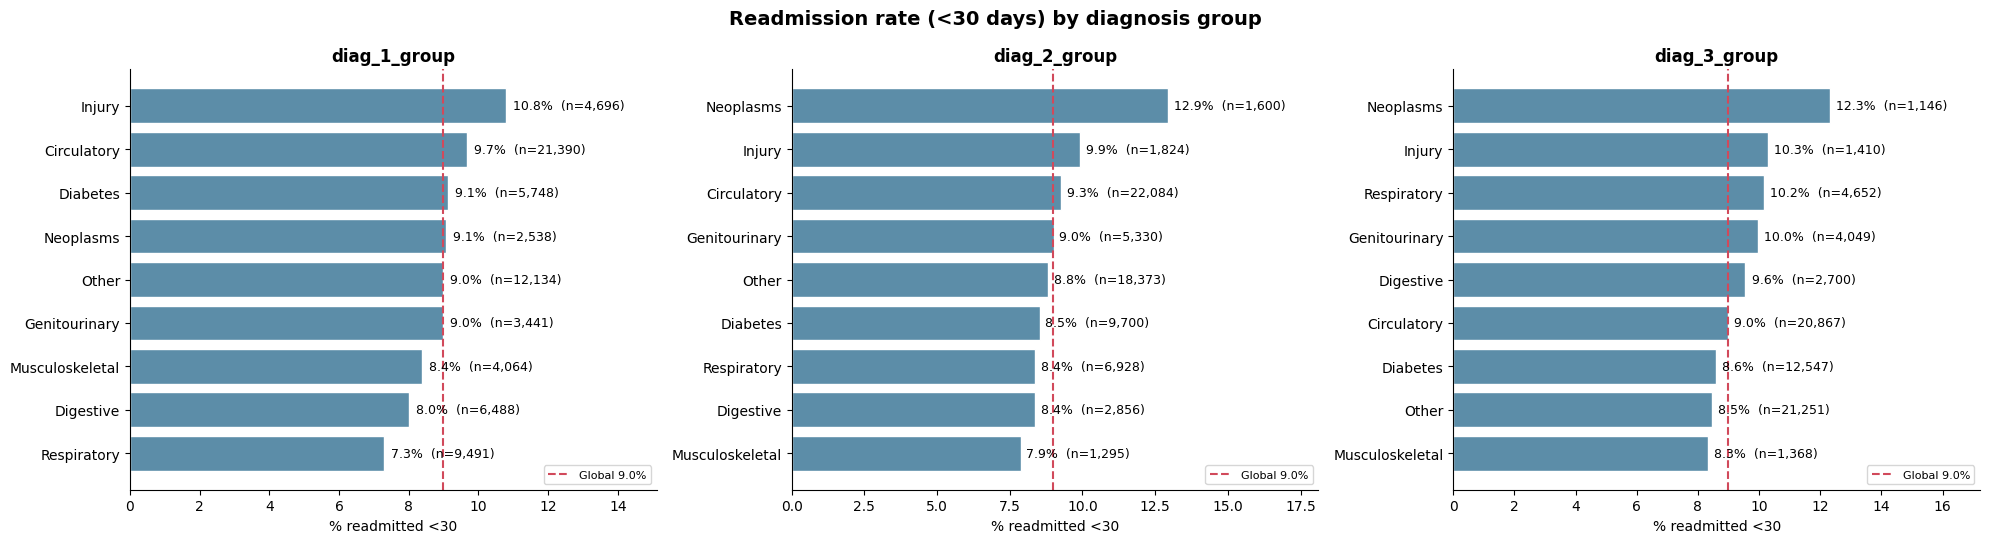

In [ ]:
diag_cols = ['diag_1_group', 'diag_2_group', 'diag_3_group']
tasa_global = df['readmitted_binary'].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, col in zip(axes, diag_cols):
    t = df.groupby(col)['readmitted_binary'].agg(['mean', 'count']).sort_values('mean')
    bars = ax.barh(t.index, t['mean'] * 100, color='#5C8DA8', edgecolor='white')
    for b, (rate, n) in zip(bars, zip(t['mean'] * 100, t['count'])):
        ax.text(rate + 0.2, b.get_y() + b.get_height()/2, f'{rate:.1f}%  (n={n:,})',
                va='center', fontsize=9)
    ax.axvline(tasa_global, color='#D1495B', linestyle='--', label=f'Global {tasa_global:.1f}%')
    ax.set_title(col, weight='bold')
    ax.set_xlabel('% readmitted <30')
    ax.set_xlim(0, t['mean'].max() * 100 * 1.4)
    ax.legend(fontsize=8, loc='lower right')
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Readmission rate (<30 days) by diagnosis group', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# delete the original columns, keep ['diag_1_group', 'diag_2_group', 'diag_3_group']
df = df.drop(columns=['diag_1', 'diag_2', 'diag_3'], errors='ignore')
df.columns.tolist()

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'insulin',
 'change',
 'diabetesMed',
 'readmitted',
 'readmitted_binary',
 'discharge_group',
 'admission_source_group',
 'admission_type_group',
 'diag_1_group',
 'diag_2_group',
 'diag_3_group']

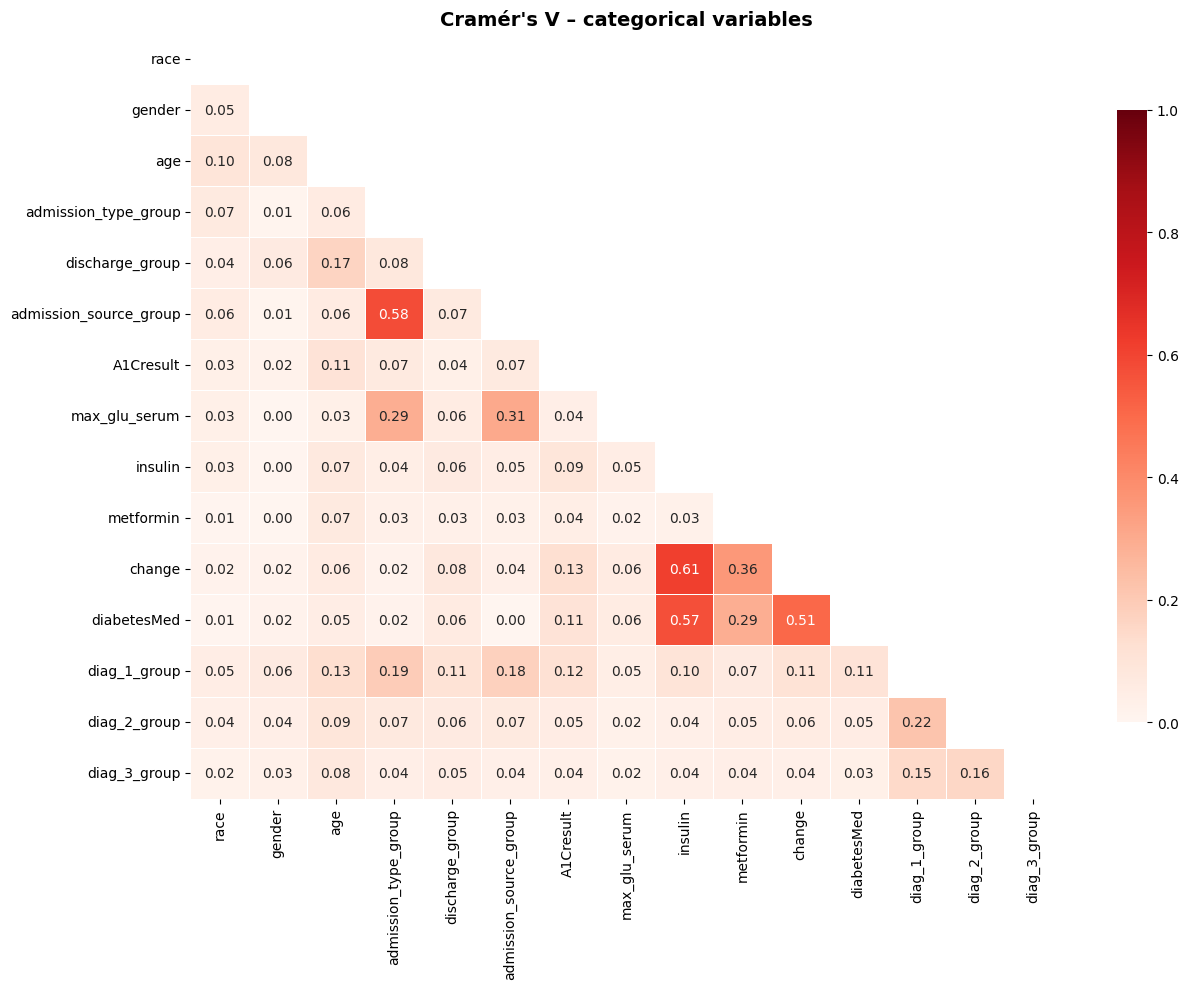

In [ ]:
# 9. Correlation Analysis and Feature Selection
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    r, k = tabla.shape
    # corrección de Bergsma: evita valores inflados con muchas categorías
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))

cat_final = ['race', 'gender', 'age', 'admission_type_group', 'discharge_group',
             'admission_source_group', 'A1Cresult', 'max_glu_serum', 'insulin',
             'metformin', 'change', 'diabetesMed',
             'diag_1_group', 'diag_2_group', 'diag_3_group']

matriz = pd.DataFrame(index=cat_final, columns=cat_final, dtype=float)
for a in cat_final:
    for b in cat_final:
        matriz.loc[a, b] = cramers_v(df[a], df[b])

mask = np.triu(np.ones_like(matriz, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(matriz, mask=mask, annot=True, fmt='.2f', cmap='Reds',
            vmin=0, vmax=1, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title("Cramér's V – categorical variables", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

In [ ]:
resultados = []
for col in cat_final:
    tabla = pd.crosstab(df[col], df['readmitted_binary'])
    chi2, p, dof, _ = chi2_contingency(tabla)
    resultados.append({
        'variable': col,
        'chi2': round(chi2, 1),
        'dof': dof,
        'p_value': p,
        'cramers_v': round(cramers_v(df[col], df['readmitted_binary']), 3)
    })

chi_target = pd.DataFrame(resultados).sort_values('cramers_v', ascending=False)
chi_target['significant'] = chi_target['p_value'] < 0.05
display(chi_target.style.format({'p_value': '{:.2e}'}))

,variable,chi2,dof,p_value,cramers_v,significant
4,discharge_group,1165.700000,5,7.78e-250,0.129000,True
2,age,189.000000,9,6.75e-36,0.051000,True
12,diag_1_group,73.700000,8,9.11e-13,0.031000,True
11,diabetesMed,53.600000,1,2.50e-13,0.027000,True
8,insulin,49.700000,3,9.17e-11,0.026000,True
13,diag_2_group,44.400000,8,4.87e-07,0.023000,True
14,diag_3_group,42.300000,8,1.19e-06,0.022000,True
10,change,14.700000,1,1.28e-04,0.014000,True
9,metformin,13.900000,3,2.99e-03,0.013000,True
0,race,11.900000,4,1.84e-02,0.011000,True


<b>Chi-square test and Cramér’s V – categorical variables vs. target</b>

Each categorical variable was tested against readmitted_binary using the chi-square test of independence. Cramér’s V was used to measure the strength of the association, since with ~70,000 records almost any small difference becomes statistically significant.

Strongest association</br>
discharge_group (V = 0.129) is by far the most important categorical variable, more than twice the strength of the next one.

Moderate association</br>
age (0.051), diag_1_group (0.031), diabetesMed (0.027), insulin (0.026), diag_2_group (0.023) and diag_3_group (0.022).

Very weak association (statistically significant, but V ≤ 0.014)</br>

change, metformin, race, admission_type_group and admission_source_group. Their significance is driven mainly by the large sample size rather than by a meaningful relationship. admission_source_group lost most of its signal after grouping.

No significant association (p ≥ 0.05)

A1Cresult, max_glu_serum and gender were removed.

<b>Cramér’s V – redundancy among categorical predictors</b>

Redundant variables (V > 0.5)

change, insulin and diabetesMed are strongly associated with each other (V between 0.51 and 0.61), since all three describe whether the patient received diabetes medication and whether it was changed. Only insulin was kept: its four levels (No, Steady, Up, Down) capture both medication use and dose changes, and its association with the target (0.026) is practically the same as diabetesMed (0.027).
admission_type_group and admission_source_group are also strongly associated (V = 0.58); both had already been removed due to their weak association with the target.

Non-redundant variables

diag_1_group, diag_2_group and diag_3_group show low associations with each other (V between 0.15 and 0.22), meaning each provides different information. All three were kept.
metformin is only moderately associated with change (V = 0.36), but its association with the target is very weak (V = 0.013), so it was removed for simplicity.

<b>Final feature selection</b> (13 variables)

Numerical (7)	Categorical (6)
time_in_hospital	discharge_group
num_lab_procedures	age
num_medications	insulin
number_outpatient	diag_1_group
number_emergency	diag_2_group
number_inpatient	diag_3_group
number_diagnoses

The original 50 variables were reduced to 13 predictors, all associated with the target and without strong redundancy among them.

In [ ]:
columnas_a_borrar = [
    # Identificadores (no son predictoras)
    'encounter_id', 'patient_nbr',
    # Target original (se reemplazó por readmitted_binary → leakage si queda)
    'readmitted',
    # Sin relación con el target
    'num_procedures', 'gender', 'A1Cresult', 'max_glu_serum',
    # Asociación muy débil con el target
    'race', 'admission_type_group', 'admission_source_group', 'metformin',
    # Redundantes con insulin
    'change', 'diabetesMed',
]

df = df.drop(columns=columnas_a_borrar, errors='ignore')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 69990 entries, 8 to 101765
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   age                 69990 non-null  object
 1   time_in_hospital    69990 non-null  int64 
 2   num_lab_procedures  69990 non-null  int64 
 3   num_medications     69990 non-null  int64 
 4   number_outpatient   69990 non-null  int64 
 5   number_emergency    69990 non-null  int64 
 6   number_inpatient    69990 non-null  int64 
 7   number_diagnoses    69990 non-null  int64 
 8   insulin             69990 non-null  object
 9   readmitted_binary   69990 non-null  int64 
 10  discharge_group     69990 non-null  object
 11  diag_1_group        69990 non-null  object
 12  diag_2_group        69990 non-null  object
 13  diag_3_group        69990 non-null  object
dtypes: int64(8), object(6)
memory usage: 8.0+ MB


# Data Preprocessing and Modeling

In [ ]:
df = df.reset_index(drop=True)

# age:  '[70-80]'
df['age'] = df['age'].str.extract(r'\[(\d+)')[0].astype(int)

visit_feats = ['number_outpatient', 'number_emergency', 'number_inpatient']
other_num   = ['time_in_hospital', 'num_lab_procedures', 'num_medications',
               'number_diagnoses', 'age']
cat_feats   = ['discharge_group', 'insulin', 'diag_1_group', 'diag_2_group', 'diag_3_group']

X = df[visit_feats + other_num + cat_feats]
y = df['readmitted_binary']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape, f'{y_train.mean():.1%} positivos')
print('Test: ', X_test.shape,  f'{y_test.mean():.1%} positivos')

Train: (55992, 13) 9.0% positivos
Test:  (13998, 13) 9.0% positivos


Each model requires a different preprocessing approach:
- Logistic Regression: Applies log1p to visit-related features to address their skewed distributions, standardizes numerical features, and encodes categorical features using one-hot encoding.
- Tree-Based Models (Random Forest and LightGBM): Do not require feature scaling or numerical transformations; only categorical features are converted using one-hot encoding.

In [ ]:
# 10. Pre-processing - Modeling
prep_lr = ColumnTransformer([
    ('visits', Pipeline([('log', FunctionTransformer(np.log1p)),
                         ('scale', StandardScaler())]), visit_feats),
    ('num', StandardScaler(), other_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_feats),
])

prep_tree = ColumnTransformer([
    ('num', 'passthrough', visit_feats + other_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_feats),
])

models = {
    'Logistic Regression': Pipeline([
        ('prep', prep_lr),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1000))]),

    'Random Forest': Pipeline([
        ('prep', prep_tree),
        ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=50,
                                         class_weight='balanced_subsample',
                                         n_jobs=-1, random_state=42))]),

    'LightGBM': Pipeline([
        ('prep', prep_tree),
        ('model', LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31,
                                 min_child_samples=100, subsample=0.8, subsample_freq=1,
                                 colsample_bytree=0.8, class_weight='balanced',
                                 random_state=42, verbose=-1))]),
}

<b>Models implemented</b>

1. Logistic Regression
A linear model that estimates the probability of readmission as a weighted combination of the predictors. It is simple, fast and highly interpretable: each coefficient shows how a variable increases or decreases the risk. It serves as the baseline model. Visit variables were log-transformed (log1p) to reduce skewness, numerical variables were standardized, and categorical variables were one-hot encoded.

2. Random Forest
An ensemble of decision trees, each trained on a random sample of records and variables. The final prediction is the average of all trees. It captures non-linear relationships and interactions between variables without requiring scaling or transformations, and it is robust to outliers. A minimum leaf size (min_samples_leaf=50) was set to prevent overfitting.

3. LightGBM (Gradient Boosting)
Also an ensemble of decision trees, but built sequentially: each new tree focuses on correcting the errors of the previous ones. It usually achieves the best performance on tabular data and is efficient on large datasets. A low learning rate, row and column subsampling, and a minimum number of samples per leaf were used to control overfitting.

Class imbalance: all three models use class weights (class_weight='balanced'), which give roughly 10 times more weight to errors on the minority class (readmitted <30 days), compensating for the imbalance without generating synthetic data.

Validation: models were compared using 5-fold stratified cross-validation on the training set (80%), with ROC-AUC and PR-AUC as metrics. The test set (20%) was kept aside for the final evaluation.

In [ ]:
# Cross-validation 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=['roc_auc', 'average_precision'])
    cv_scores[name] = {'ROC-AUC': s['test_roc_auc'], 'PR-AUC': s['test_average_precision']}
    print(f'{name} ✓')

tabla_cv = pd.DataFrame({
    name: {
        'ROC-AUC mean': scores['ROC-AUC'].mean(),
        'ROC-AUC std':  scores['ROC-AUC'].std(),
        'PR-AUC mean':  scores['PR-AUC'].mean(),
        'PR-AUC std':   scores['PR-AUC'].std(),
    }
    for name, scores in cv_scores.items()
}).T

display(tabla_cv.style.format('{:.3f}')
        .highlight_max(subset=['ROC-AUC mean', 'PR-AUC mean'], color='#D1E3EC'))

Logistic Regression ✓
Random Forest ✓


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM ✓


,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std
Logistic Regression,0.645,0.012,0.161,0.007
Random Forest,0.649,0.011,0.165,0.006
LightGBM,0.643,0.013,0.167,0.007


Logistic Regression ✓
Random Forest ✓


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM ✓


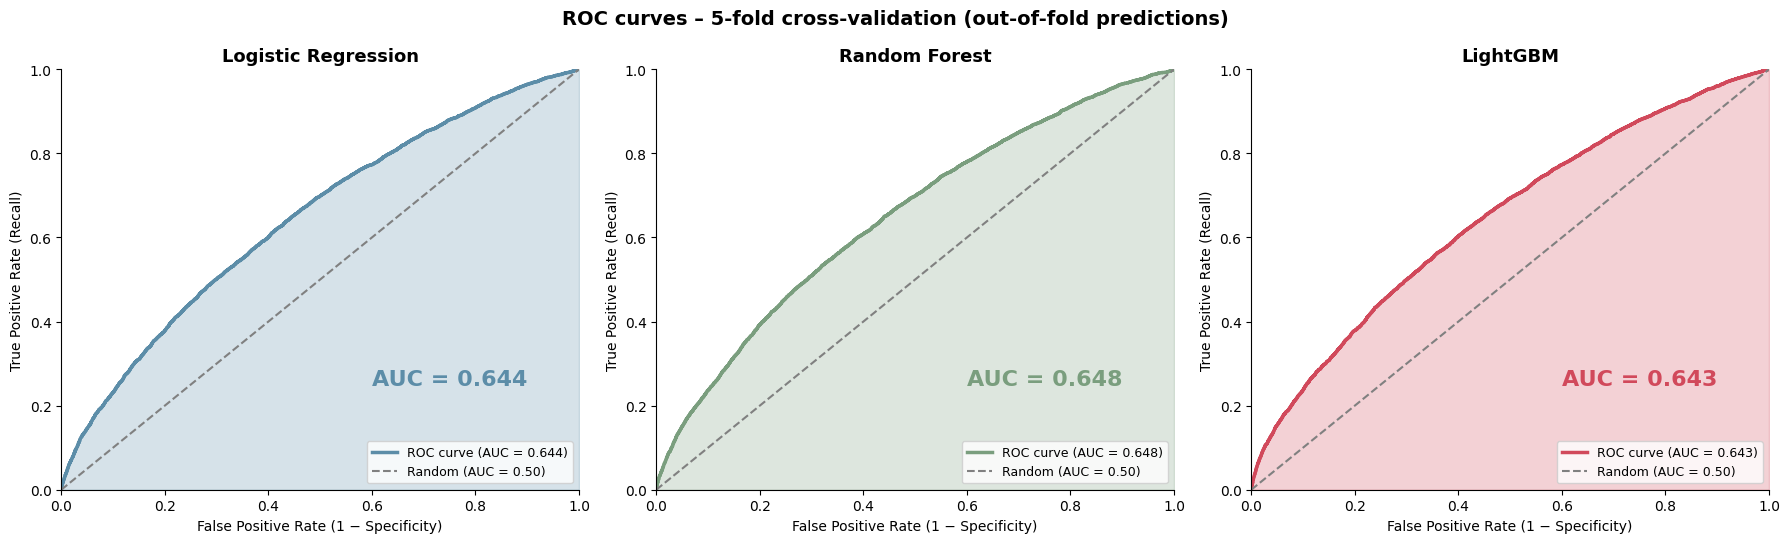

In [ ]:
# Probabilities out-of-fold
oof_probs = {}
for name, model in models.items():
    oof_probs[name] = cross_val_predict(model, X_train, y_train, cv=cv,
                                        method='predict_proba')[:, 1]
    print(f'{name} ✓')

# ROC graphic by model
colores = {'Logistic Regression': '#5C8DA8', 'Random Forest': '#7A9E7E', 'LightGBM': '#D1495B'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, probs) in zip(axes, oof_probs.items()):
    fpr, tpr, _ = roc_curve(y_train, probs)
    auc = roc_auc_score(y_train, probs)

    ax.plot(fpr, tpr, color=colores[name], linewidth=2.5, label=f'ROC curve (AUC = {auc:.3f})')
    ax.fill_between(fpr, tpr, alpha=0.25, color=colores[name])
    ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random (AUC = 0.50)')
    ax.text(0.6, 0.25, f'AUC = {auc:.3f}', fontsize=16, weight='bold', color=colores[name])

    ax.set_title(name, fontsize=13, weight='bold')
    ax.set_xlabel('False Positive Rate (1 − Specificity)')
    ax.set_ylabel('True Positive Rate (Recall)')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(loc='lower right', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('ROC curves – 5-fold cross-validation (out-of-fold predictions)',
             fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

<b>ROC curves – 5-fold cross-validation (out-of-fold predictions)</b>

Logistic Regression (AUC = 0.644)
The curve stays consistently above the random diagonal, showing that the model ranks readmitted patients above non-readmitted ones better than chance. At a false positive rate of 20%, it detects about 40% of the patients readmitted within 30 days. Its performance is practically identical to the tree-based models, with the advantage of being the simplest and most interpretable.

Random Forest (AUC = 0.648)
It shows the highest AUC, but only by 0.004 over Logistic Regression, a difference smaller than the variability between folds (±0.011). The curve is smooth and very similar in shape to the other two, suggesting that it does not find relevant non-linear patterns or interactions beyond those captured by the linear model.

LightGBM (AUC = 0.643)
Despite being the most complex model, it performs at the same level as the other two. This confirms that the predictive signal in the selected variables is mostly linear and that additional model complexity does not improve discrimination.

Overall
The three curves are almost identical and achieve a modest discriminative ability (AUC ≈ 0.64–0.65), consistent with published results for this dataset. The limitation lies in the information available in the data, not in the choice of algorithm. Given equal performance, Logistic Regression is preferred for its simplicity and interpretability, which are key for explaining readmission risk to clinical and business stakeholders.

# Evaluation

In [ ]:
umbrales = np.round(np.arange(0.30, 0.76, 0.05), 2)

for name, probs in oof_probs.items():
    filas = []
    for t in umbrales:
        pred = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
        filas.append({
            'threshold': t,
            'precision': precision_score(y_train, pred, zero_division=0),
            'recall': recall_score(y_train, pred),
            'specificity': tn / (tn + fp),
            'accuracy': accuracy_score(y_train, pred),
            'f1': f1_score(y_train, pred),
            '% flagged': pred.mean(),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        })
    tabla = pd.DataFrame(filas).set_index('threshold')

    print(f'\n=== {name} ===')
    display(tabla.style
            .format('{:.3f}', subset=['precision', 'recall', 'specificity', 'accuracy', 'f1', '% flagged'])
            .format('{:,}', subset=['TP', 'FP', 'FN', 'TN'])
            .highlight_max(subset=['f1'], color='#D1E3EC'))


=== Logistic Regression ===


,precision,recall,specificity,accuracy,f1,% flagged,TP,FP,FN,TN
threshold,,,,,,,,,,
0.300000,0.091,0.992,0.022,0.109,0.167,0.980,"4,989","49,856",39,"1,108"
0.350000,0.097,0.946,0.134,0.207,0.176,0.874,"4,759","44,158",269,"6,806"
0.400000,0.109,0.820,0.338,0.381,0.192,0.676,"4,125","33,744",903,"17,220"
0.450000,0.124,0.663,0.539,0.550,0.209,0.479,"3,336","23,500","1,692","27,464"
0.500000,0.137,0.530,0.671,0.658,0.218,0.347,"2,664","16,758","2,364","34,206"
0.550000,0.153,0.416,0.773,0.741,0.224,0.244,"2,090","11,547","2,938","39,417"
0.600000,0.174,0.302,0.858,0.808,0.220,0.156,"1,516","7,218","3,512","43,746"
0.650000,0.198,0.199,0.921,0.856,0.198,0.090,999,"4,044","4,029","46,920"
0.700000,0.229,0.136,0.955,0.881,0.171,0.053,684,"2,309","4,344","48,655"



=== Random Forest ===


,precision,recall,specificity,accuracy,f1,% flagged,TP,FP,FN,TN
threshold,,,,,,,,,,
0.300000,0.095,0.968,0.089,0.168,0.173,0.916,"4,867","46,413",161,"4,551"
0.350000,0.102,0.904,0.213,0.275,0.183,0.798,"4,543","40,123",485,"10,841"
0.400000,0.113,0.786,0.391,0.427,0.197,0.625,"3,950","31,033","1,078","19,931"
0.450000,0.127,0.641,0.565,0.572,0.212,0.453,"3,225","22,149","1,803","28,815"
0.500000,0.144,0.500,0.708,0.689,0.224,0.311,"2,515","14,892","2,513","36,072"
0.550000,0.169,0.334,0.838,0.793,0.224,0.178,"1,680","8,267","3,348","42,697"
0.600000,0.214,0.178,0.935,0.867,0.194,0.075,896,"3,290","4,132","47,674"
0.650000,0.251,0.092,0.973,0.894,0.135,0.033,462,"1,375","4,566","49,589"
0.700000,0.312,0.039,0.992,0.906,0.069,0.011,196,432,"4,832","50,532"



=== LightGBM ===


,precision,recall,specificity,accuracy,f1,% flagged,TP,FP,FN,TN
threshold,,,,,,,,,,
0.300000,0.101,0.907,0.199,0.263,0.181,0.810,"4,561","40,811",467,"10,153"
0.350000,0.107,0.839,0.309,0.357,0.190,0.704,"4,218","35,220",810,"15,744"
0.400000,0.116,0.742,0.441,0.468,0.200,0.575,"3,733","28,487","1,295","22,477"
0.450000,0.128,0.622,0.580,0.584,0.212,0.438,"3,129","21,396","1,899","29,568"
0.500000,0.142,0.493,0.706,0.687,0.220,0.312,"2,480","14,994","2,548","35,970"
0.550000,0.159,0.372,0.806,0.767,0.223,0.210,"1,872","9,894","3,156","41,070"
0.600000,0.185,0.263,0.885,0.830,0.217,0.128,"1,324","5,836","3,704","45,128"
0.650000,0.220,0.175,0.939,0.870,0.195,0.071,878,"3,106","4,150","47,858"
0.700000,0.260,0.114,0.968,0.891,0.158,0.039,571,"1,626","4,457","49,338"


In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, accuracy_score, f1_score, confusion_matrix)

threshold = 0.55   # threshold selected

final_model = models['Logistic Regression']
final_model.fit(X_train, y_train)

test_probs = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

resultados_test = pd.Series({
    'ROC-AUC': roc_auc_score(y_test, test_probs),
    'PR-AUC': average_precision_score(y_test, test_probs),
    'Precision': precision_score(y_test, test_pred),
    'Recall': recall_score(y_test, test_pred),
    'Specificity': tn / (tn + fp),
    'Accuracy': accuracy_score(y_test, test_pred),
    'F1': f1_score(y_test, test_pred),
}, name=f'Test (threshold = {threshold})')

display(resultados_test.to_frame().style.format('{:.3f}'))
print(f'TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}')

,Test (threshold = 0.55)
ROC-AUC,0.647
PR-AUC,0.167
Precision,0.154
Recall,0.418
Specificity,0.774
Accuracy,0.742
F1,0.225


TP=526  FP=2,883  FN=731  TN=9,858


<b>Generalization:</b> test results (ROC-AUC 0.647, PR-AUC 0.167) are almost identical to cross-validation (0.644 and 0.161), confirming that the model is not overfitted and that these figures reflect its real expected performance.

<b>Discrimination:</b> a ROC-AUC of 0.647 indicates a modest ability to rank readmitted patients above non-readmitted ones, consistent with published results for this dataset. The PR-AUC (0.167) is nearly twice the random baseline (0.09).

<b>Classification at threshold 0.55:</b>

The model flags 3,409 patients (24% of the test set) as high risk.
It detects 526 of the 1,257 patients readmitted within 30 days (recall = 41.8%).
Among flagged patients, 15.4% are readmitted (precision), compared with the 9% base rate, which is 1.7 times higher.
It correctly identifies 77.4% of non-readmitted patients (specificity).
Accuracy (74.2%) is not a meaningful metric here because of the class imbalance: a model predicting “no readmission” for everyone would reach 91%.

<b>Business interpretation:</b> by following up on 24% of patients selected by the model, the hospital would reach 42% of all 30-day readmissions, nearly twice the 24% expected from random selection with the same resources. The threshold can be lowered to increase recall if missing a high-risk patient is considered more costly than additional follow-ups.

<b>Limitation:</b> all three algorithms reached the same performance ceiling, indicating that the limitation lies in the available data (lack of clinical, social and post-discharge information) rather than in the modeling approach.